# Deep hedging under transaction costs

**Question:** can a neural policy improve the cost–risk balance of hedging a European call?

This notebook explains the finance, describes a frozen experiment, and reads the bundled final results. It compares two neural architectures against increasingly strong financial rules. Every training seed is reported. The study uses simulated prices; it makes no claim of real-market trading performance.

Implementation lives in [`hedging.py`](hedging.py), so accounting, training and evaluation have one source of truth. The original exploratory notebook has been consolidated into this walkthrough. Selected historical results are separately labelled in `results/exploratory/`.

## 1. Setup

Use Python 3.11 and install `requirements.txt`. By default, **Run All reads saved results without retraining**. The optional training switch below launches the full experiment only when explicitly enabled. Start the notebook from the repository directory.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import display, Image, Markdown

try:
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print("TensorFlow already initialized; keeping this kernel's thread settings.")

from hedging import (
    Config, account, simulate_paths, call_delta, delta_targets,
    band_holdings, entropic_risk, select_bands, run_experiment,
)
from reporting import make_figures

ROOT = Path.cwd()
assert (ROOT / "hedging.py").exists(), "Start Jupyter from the repository directory."
RUN_DIR = ROOT / "results" / "full"
RUN_TRAINING = False
config = Config()

## 2. The obligation we hedge

We sell one call on one share. The buyer pays an upfront premium; at expiry we owe

$$\max(S_T-K,0).$$

With a $100 strike and a final price of $130, the cash payment is $30. Owning stock can offset rising exposure, but buying that stock uses cash, and subsequent adjustments incur costs.

Our assumptions are a $100 initial stock price, 20 trading days to expiry, 20% annualized volatility, zero expected stock return, zero interest and no dividends. The Black–Scholes premium is about $2.25, consistent with those assumptions. A hypothetical $5 premium used during exploration is not used in the final experiment.

P&L is measured in dollars per option on one share. All stock trades, including the opening position and final liquidation, incur a cost of 0.1% of value traded. Negative cash is borrowing; zero interest does not mean free stock purchases.

In [2]:
print(f"Option premium: ${config.premium:.4f}")
initial_delta = call_delta(100.0, config.strike, config.volatility, config.maturity)
print(f"Initial delta: {initial_delta:.4f} shares")

example = np.array([[100.0, 110.0, 105.0, 130.0]])
example_holdings = np.array([[0.50, 0.65, 0.55]])
ledger = account(example, example_holdings, config)
display(pd.DataFrame(ledger).round(4))

Option premium: $2.2475
Initial delta: 0.5112 shares


,pnl,gross_pnl,costs,turnover
0,-12.401,-12.2525,0.1485,148.5


The numerical identity used throughout is

$$\mathrm{P\&L}=\mathrm{premium}+\sum_t h_t(S_{t+1}-S_t)
-\mathrm{option\ payoff}-\mathrm{transaction\ costs}.$$

This is equivalent to the cash ledger when interest is zero. The holding $h_t$ is chosen after observing $S_t$, before $S_{t+1}$ is known. The accounting tests also compare this calculation with the differentiable TensorFlow ledger.

## 3. Simulated market experiences

Each row below is a different possible future for the **same stock**, not a different stock. Geometric Brownian motion keeps prices positive and fixes the scale of random returns. The model has constant volatility, independent shocks and no jumps. It is a controlled training environment rather than a price forecast.

In [3]:
example_paths = simulate_paths(1000, 42, config)
print("Shape:", example_paths.shape)
print("First path:", np.round(example_paths[0], 2))

Shape: (1000, 21)
First path: [100.   100.38  99.06 100.   101.18  98.71  97.1   97.25  96.86  96.83
  95.78  96.84  97.79  97.86  99.26  99.83  98.75  99.2   98.    99.09
  99.02]


## 4. Strategies and a strong benchmark

| Strategy | Decision |
|---|---|
| No hedge | Hold no stock |
| Half-share | Hold 0.5 shares until expiry |
| Delta | Rebalance daily to Black–Scholes delta |
| Reset band | Stay put inside a band around delta; otherwise trade to delta |
| Boundary band | Stay put inside the band; otherwise trade only to its nearest edge |
| Dense network | Predict a target holding from price/strike, time remaining and existing holding |
| Learned band network | Predict price- and time-dependent lower/upper limits, then project the existing holding into that interval |

Delta estimates the call's sensitivity to a small stock-price move. A call seller buys approximately delta shares to offset that sensitivity. Exact replication assumes continuous rebalancing and idealized market conditions; our daily hedge retains risk.

The financial band rules establish delta at day zero. The networks choose their opening holding. All opening costs are charged, but this initial-position difference should be remembered when attributing results to architecture.

A simple example: current holding 0.50, delta 0.65 and width 0.075. The reset rule buys to 0.65; the boundary rule buys only to 0.575.

In [4]:
example_deltas = np.array([[0.50, 0.65, 0.58]])
print("Reset rule:   ", band_holdings(example_deltas, 0.075)[0])
print("Boundary rule:", band_holdings(example_deltas, 0.075, boundary=True)[0])

Reset rule:    [0.5  0.65 0.65]
Boundary rule: [0.5   0.575 0.575]


## 5. What the neural networks minimize

For final P&L $X$, we minimize the sample entropic risk

$$\rho_\gamma(X)=\frac{1}{\gamma}\log\left(\frac{1}{N}\sum_i e^{-\gamma X_i}\right),
\qquad \gamma=1\ \mathrm{dollar}^{-1}.$$

Lower is better. The exponential emphasizes poor outcomes; the score still rewards increasing P&L. Negative scores are valid. Transaction costs already reduce P&L and are not added again as a separate penalty. Risk aversion is a chosen financial preference, not an optimized trading signal.

The networks receive `[log(S/K), fraction of time remaining, previous holding]`. Volatility is fixed in training, so it is not an input. They never receive future prices, delta labels or target trades. Backpropagation passes through their sequence of decisions and the trading account. Holdings are constrained to [0, 1].

In [5]:
print("Always lose $0.20:", round(entropic_risk(np.array([-0.2, -0.2])), 3))
print("Equal chance of -$1 or +$1:", round(entropic_risk(np.array([-1.0, 1.0])), 3))

Always lose $0.20: 0.2
Equal chance of -$1 or +$1: 0.434


## 6. Frozen training and evaluation protocol

- Training: 50,000 paths, seed 101. Validation: 10,000 paths, seed 202.
- Both architectures use 32-unit tanh hidden layers and four initialization/shuffle seeds: 123, 456, 789, 1011.
- Adam, learning rate 0.001, batch size 1,024, gradient clipping, at most 100 epochs. Restore the checkpoint selected on validation risk, with patience 10 and a minimum improvement of 0.0001. The same rule applies from the start to every consolidated run.
- Select both financial band widths from a fixed validation grid. This grid is not an exhaustive optimization.
- Only after training/selection, generate 30,000 fresh final paths, seed 909. Every strategy faces these same paths, and every seed is reported.
- Paired bootstrap comparisons use the same resampled path indices for neural and boundary strategies. Report individual 95% percentile intervals; no multiple-comparison correction is implied.

This consolidated protocol follows exploratory development; it was not preregistered. Earlier samples (including seeds 303 and 808) are not reused as the new final sample. The original dense model had a two-stage schedule, so historical metrics need not exactly match this uniformly trained rerun.

In [6]:
if RUN_TRAINING:
    # Choose a NEW RUN_DIR first; completed results/checkpoints cannot be overwritten.
    run_experiment(config, RUN_DIR, profile="full")

if not (RUN_DIR / "manifest.json").exists():
    raise FileNotFoundError(
        "No completed run here. Run the CLI full experiment, or enable training "
        "with a new RUN_DIR."
    )

manifest = json.loads((RUN_DIR / "manifest.json").read_text())
config = Config(**json.loads((RUN_DIR / "config.json").read_text()))
print("Completed profile:", manifest["profile"])
if manifest["profile"] != "full":
    print("QUICK PROFILE: integration check only; not research evidence.")
print("TensorFlow:", manifest["tensorflow"], "| Keras:", manifest["keras"])

Completed profile: full
TensorFlow: 2.16.2 | Keras: 3.12.0


In [7]:
band_search = pd.read_csv(RUN_DIR / "band_search.csv")
selected_widths = json.loads((RUN_DIR / "selected_bands.json").read_text())
print("Validation-selected widths:", selected_widths)
display(band_search.pivot(index="width", columns="strategy", values="validation_risk").round(5))

training = pd.read_csv(RUN_DIR / "training_summary.csv")
display(training[["architecture", "seed", "best_epoch", "epochs_run", "validation_risk"]].round(5))

Validation-selected widths: {'boundary_band': 0.05, 'reset_band': 0.075}


strategy,boundary_band,reset_band
width,,
0.000,0.35024,0.35024
0.025,0.32089,0.34632
0.050,0.31860,0.34096
0.075,0.33548,0.33890
0.100,0.37071,0.34331
0.125,0.42298,0.35311
0.150,0.49043,0.36924
0.200,0.67486,0.40796
0.300,1.23563,0.55537


,architecture,seed,best_epoch,epochs_run,validation_risk
0,dense,123,97,100,0.32961
1,dense,456,99,100,0.32958
2,dense,789,98,100,0.32840
3,dense,1011,98,100,0.32909
4,learned_band,123,97,100,0.31861
5,learned_band,456,99,100,0.31753
6,learned_band,789,95,100,0.31808
7,learned_band,1011,86,96,0.31990


## 7. Final comparison: every model, one shared sample

Average P&L explains average revenue/cost; standard deviation measures overall variability; the 5th percentile describes a downside threshold, not a maximum loss. Entropic risk is our chosen decision criterion and need not rank strategies the same way as any single descriptive statistic.

The seed summary below averages **separate model scores**. It is not the risk of a pooled portfolio or an ensemble, and the models share the same evaluation paths.

In [8]:
final_metrics = pd.read_csv(RUN_DIR / "final_metrics.csv")
display(final_metrics.round(5))
display(pd.read_csv(RUN_DIR / "seed_summary.csv").round(5))

,strategy,risk,mean_pnl,std_pnl,pnl_5th_percentile,mean_cost,mean_gross_pnl
0,no_hedge,16.47316,0.01743,3.36574,-7.15225,0.00000,0.01743
1,half_share,3.10118,-0.08391,1.68613,-3.30909,0.10000,0.01608
2,delta,0.35593,-0.24488,0.44832,-1.02030,0.24075,-0.00413
3,reset_band,0.34489,-0.21832,0.48261,-1.03734,0.21441,-0.00391
4,boundary_band,0.31844,-0.18753,0.50403,-1.00852,0.18595,-0.00157
5,dense_123,0.32796,-0.20717,0.48730,-0.97922,0.20477,-0.00239
6,dense_456,0.32783,-0.20683,0.48937,-0.97217,0.20447,-0.00235
7,dense_789,0.32683,-0.20795,0.48491,-0.96788,0.20551,-0.00244
8,dense_1011,0.32760,-0.20736,0.48507,-0.97826,0.20491,-0.00245
9,learned_band_123,0.31796,-0.19253,0.50016,-0.97490,0.19014,-0.00239


,architecture,mean,std,min,max
0,dense,0.32755,0.00050,0.32683,0.32796
1,learned_band,0.31758,0.00103,0.31655,0.31884


## 8. Uncertainty relative to the strong boundary rule

The difference is `neural risk - boundary risk`. An interval entirely below zero favors the neural policy; one entirely above zero favors the boundary rule. An interval including zero does not resolve the difference at this level.

Intervals are conditional on a fitted model and this simulator. They measure Monte Carlo path-sampling uncertainty, not uncertainty from choosing the simulator, collecting a different training dataset, or changing real market conditions. Training-seed repetitions address a different source of variability.

In [9]:
intervals = pd.read_csv(RUN_DIR / "paired_intervals.csv")
display(intervals.round(5))

,strategy,reference,risk_difference,ci_lower,ci_upper
0,dense_123,boundary_band,0.00952,0.00638,0.01234
1,dense_456,boundary_band,0.00939,0.00619,0.01222
2,dense_789,boundary_band,0.00839,0.00528,0.01124
3,dense_1011,boundary_band,0.00916,0.00605,0.01201
4,learned_band_123,boundary_band,-0.00048,-0.00289,0.00186
5,learned_band_456,boundary_band,-0.00149,-0.00381,0.00073
6,learned_band_789,boundary_band,-0.00189,-0.00425,0.00032
7,learned_band_1011,boundary_band,0.00040,-0.00202,0.00266


## 9. Why strategies differ: trading expenditure

Gross P&L excludes stock transaction costs but includes the premium and option payoff. Net P&L includes the costs. Under the zero-drift, zero-interest simulator, predictable bounded stock holdings have zero expected stock gains, so average gross P&L should be near zero in the correctly specified scenario. Finite samples need not give exactly zero.

A lower cost does not automatically imply a better hedge: spending less can expose the option seller to larger losses. Compare the full risk objective as well as costs.

In [10]:
display(final_metrics[[
    "strategy", "mean_cost", "mean_gross_pnl", "mean_pnl", "risk"
]].round(5))

,strategy,mean_cost,mean_gross_pnl,mean_pnl,risk
0,no_hedge,0.00000,0.01743,0.01743,16.47316
1,half_share,0.10000,0.01608,-0.08391,3.10118
2,delta,0.24075,-0.00413,-0.24488,0.35593
3,reset_band,0.21441,-0.00391,-0.21832,0.34489
4,boundary_band,0.18595,-0.00157,-0.18753,0.31844
5,dense_123,0.20477,-0.00239,-0.20717,0.32796
6,dense_456,0.20447,-0.00235,-0.20683,0.32783
7,dense_789,0.20551,-0.00244,-0.20795,0.32683
8,dense_1011,0.20491,-0.00245,-0.20736,0.32760
9,learned_band_123,0.19014,-0.00239,-0.19253,0.31796


## 10. Volatility misspecification

Generate new paths with actual volatility 10%, 20%, 30%, or 40%, while keeping the premium, assumed 20% volatility, all network weights, costs and selected widths unchanged. The same underlying random shocks are used across volatility scenarios; scenarios are therefore not independent of each other.

An unexpected volatility increase makes the option obligation more expensive on average. The original premium may be insufficient, and hedging does not create expected stock profits to repair that shortfall. Compare strategies **within** a scenario. These scenarios have constant volatility, not stochastic-volatility dynamics. Entropic scores are especially sensitive to rare losses at high volatility.

In [11]:
stress = pd.read_csv(RUN_DIR / "stress_metrics.csv")
display(stress.pivot(index="strategy", columns="actual_volatility", values="risk").round(5))

actual_volatility,0.1,0.2,0.3,0.4
strategy,,,,
boundary_band,-0.88302,0.31319,1.82813,4.32034
delta,-0.86917,0.35277,2.03282,4.99767
dense_1011,-0.87822,0.32361,1.76446,3.93772
dense_123,-0.87733,0.32412,1.75813,3.91885
dense_456,-0.87607,0.32398,1.74834,3.88283
dense_789,-0.87586,0.32292,1.75029,3.89302
half_share,-0.55342,2.57002,8.29432,15.93848
learned_band_1011,-0.88275,0.31429,1.79349,4.22256
learned_band_123,-0.88437,0.31297,1.79516,4.21898


## 11. Figures and learned policy inspection

Figures are generated from the saved results. Representative distribution and boundary plots use seed 123, chosen in advance rather than selected for its final performance. The shaded ranges in the stress chart show variation across seed scores, not confidence intervals.

Boundary plots inspect hypothetical price/time states. Some combinations are rare in the training data. They help explain behavior but do not establish optimality.

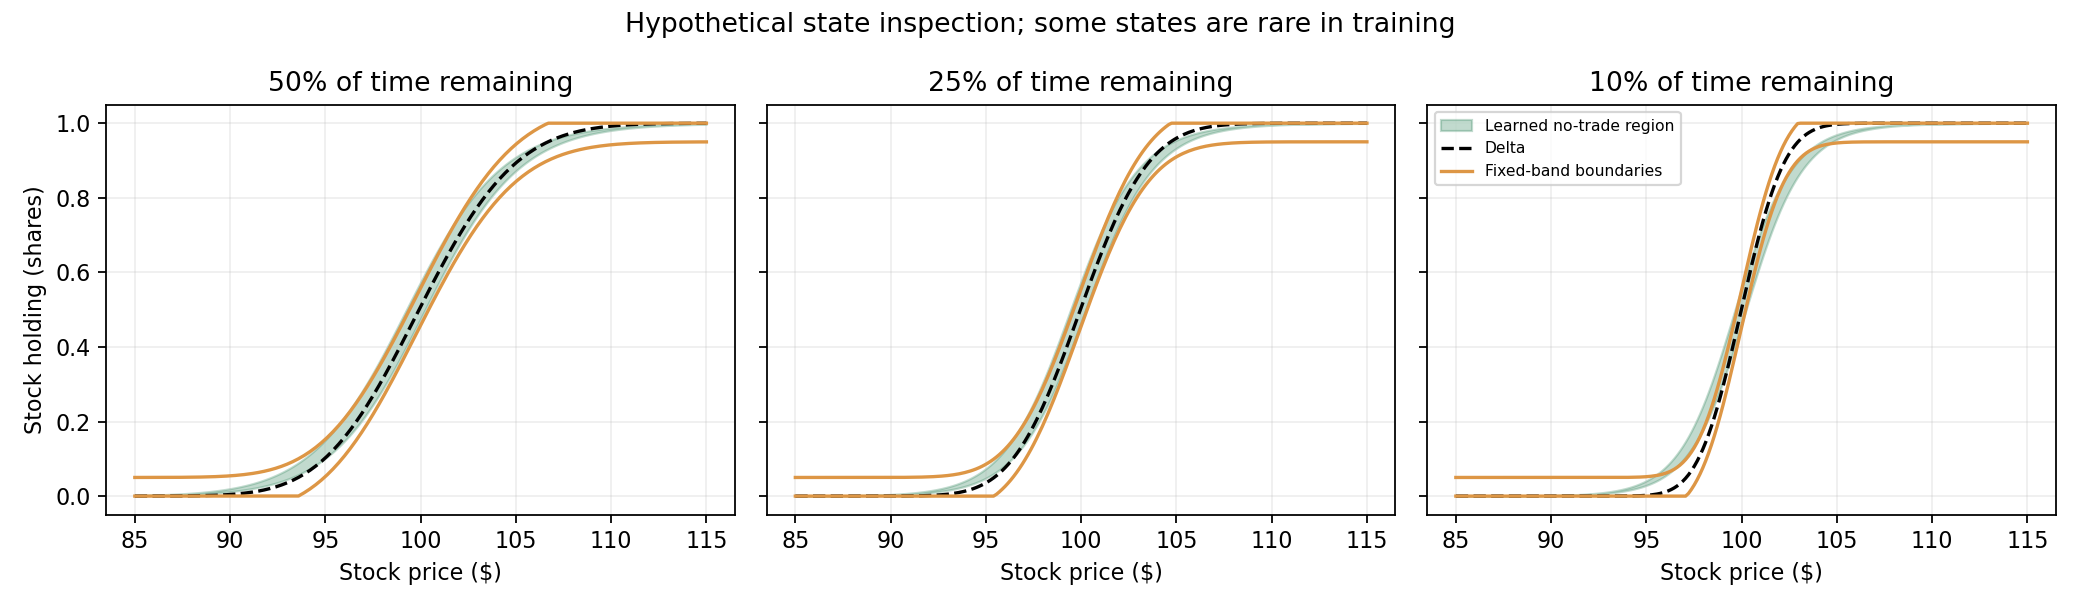

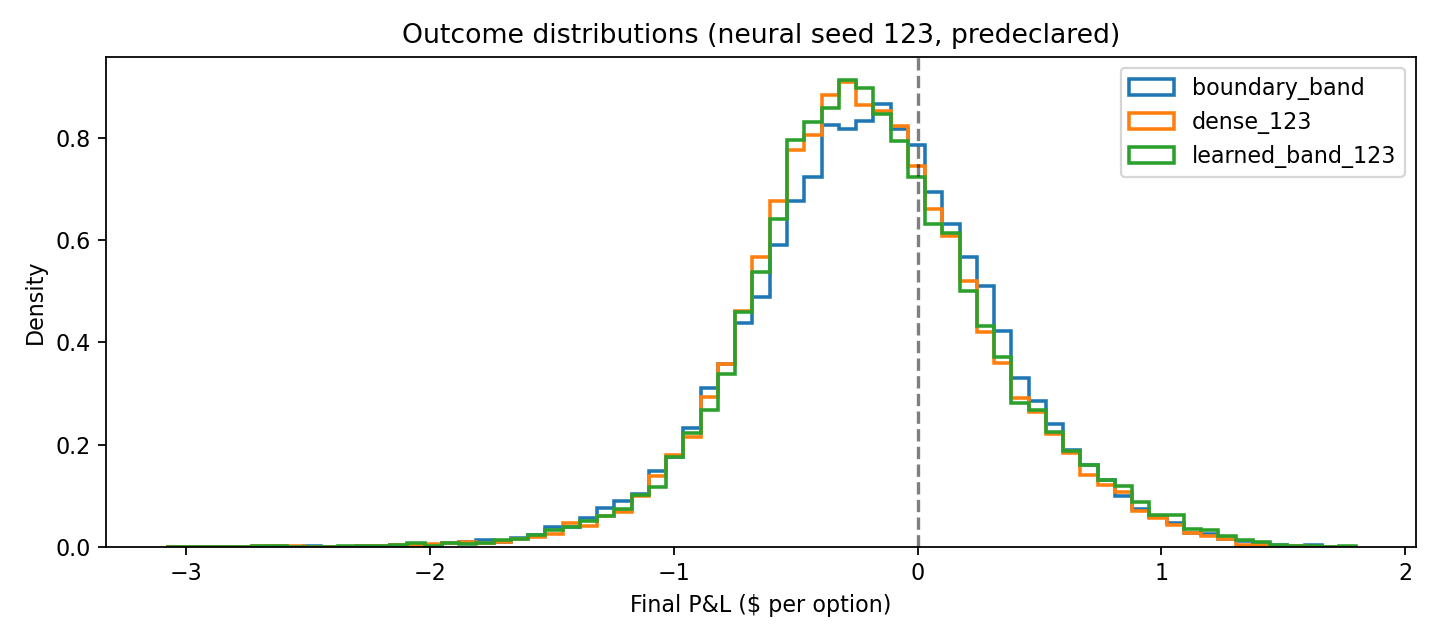

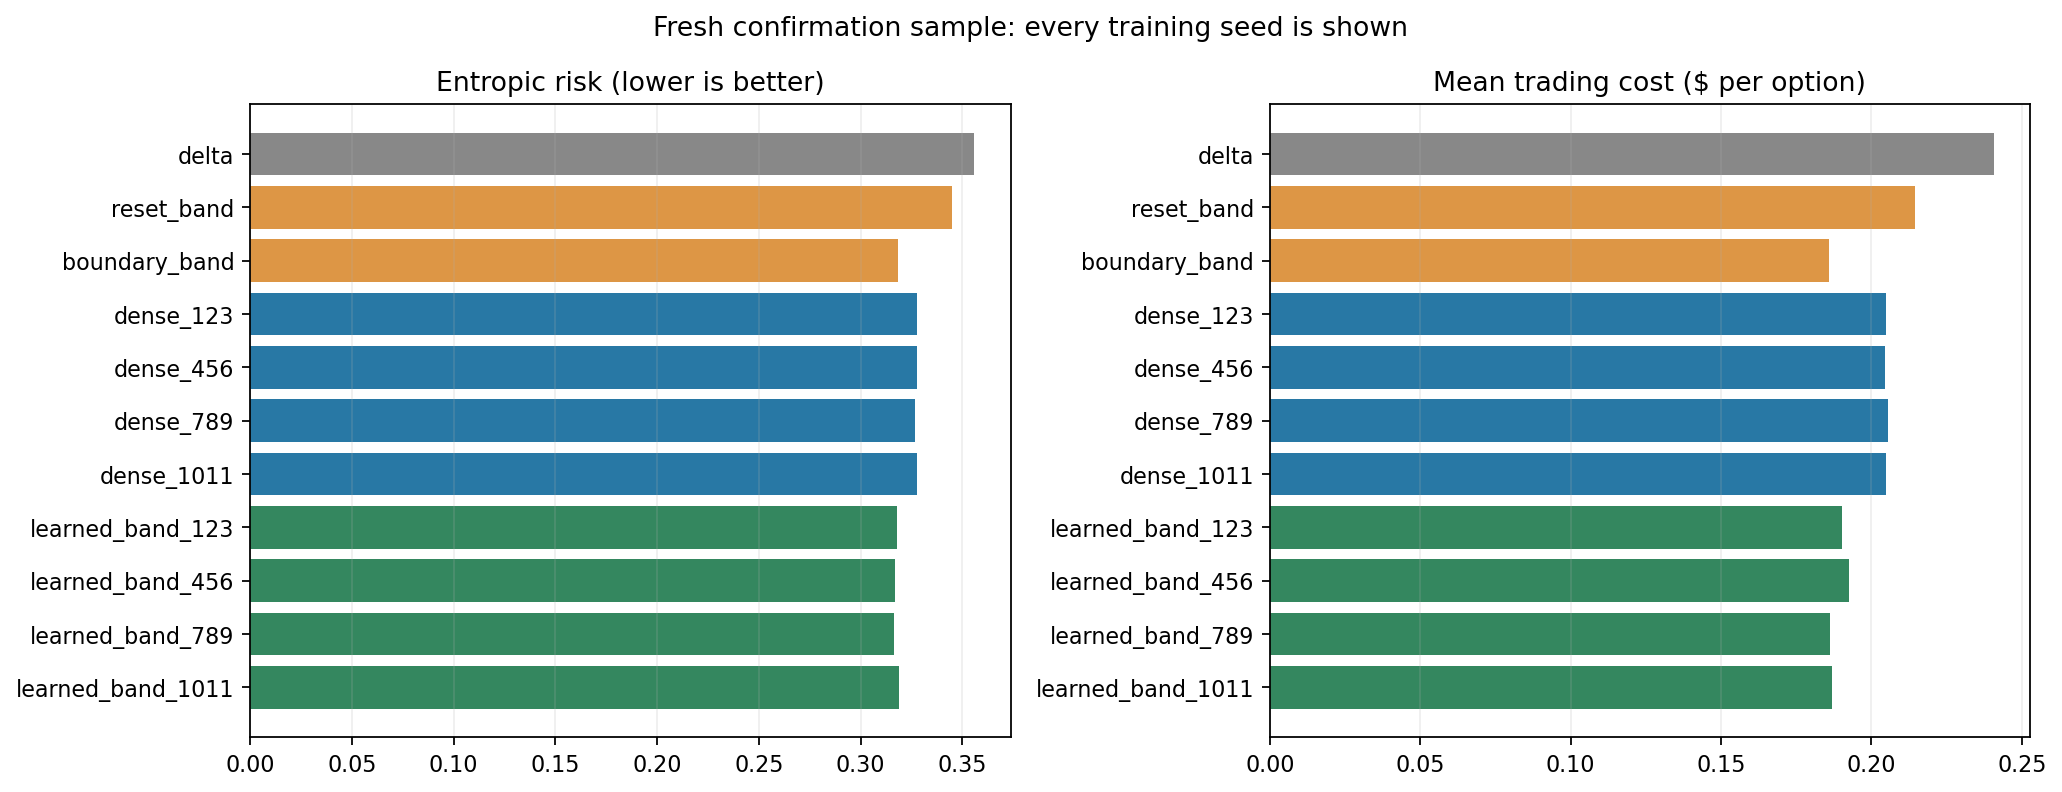

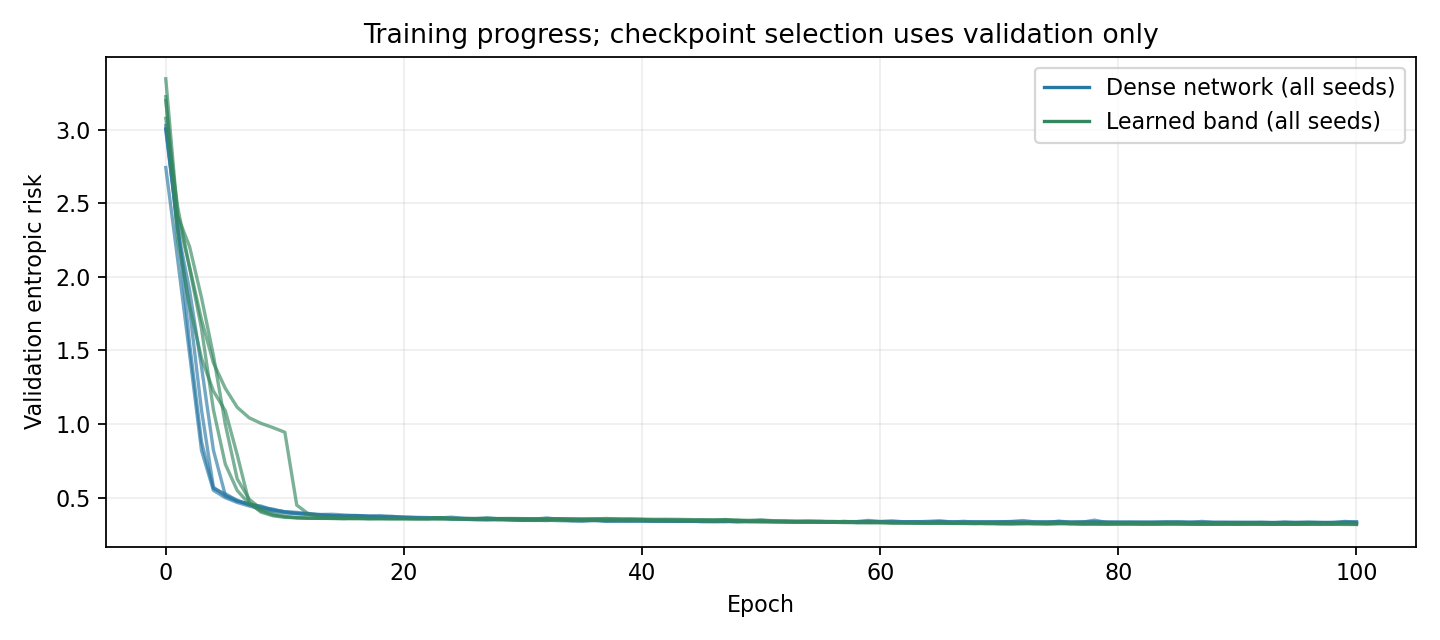

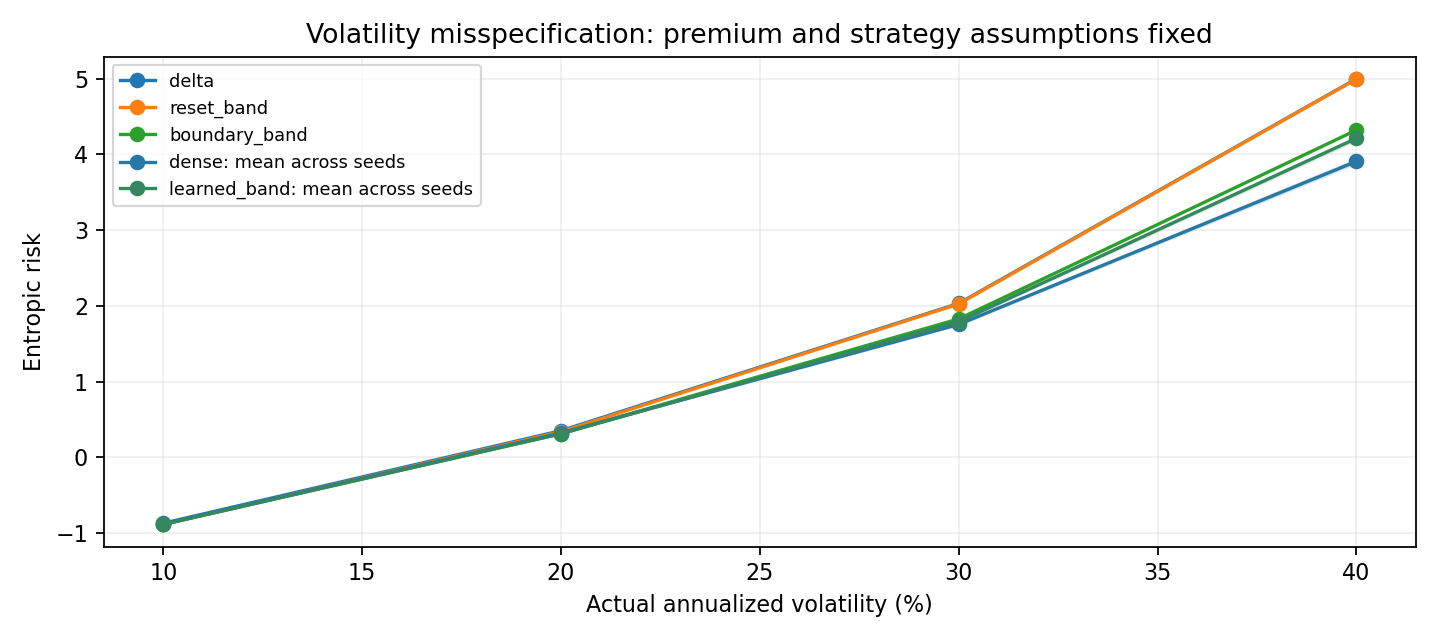

In [12]:
figure_paths = make_figures(RUN_DIR, config)
for figure in figure_paths:
    display(Image(filename=str(figure)))

## 12. Verification

The checks cover self-financing accounting, opening/liquidation costs, the zero-width band identity, numerical risk calculations, TensorFlow/NumPy agreement, no use of future prices, exact inaction inside learned boundaries, and checkpoint serialization. They do not assert that a neural model must outperform a financial rule.

In [13]:
import unittest

suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"))
check_result = unittest.TextTestRunner(verbosity=1).run(suite)
assert check_result.wasSuccessful(), "A verification check failed."

.......
----------------------------------------------------------------------
Ran 7 tests in 0.269s

OK


## 13. Interpretation and limits

The exploratory result changed as the benchmark improved: the dense network beat a reset-to-delta band, while a stronger boundary rule exposed a trading-cost disadvantage. Adding an explicit no-trade architecture largely closed that gap on validation data. The final tables above establish what held on fresh paths, including variation across runs and uncertainty against the strong rule. A small lead or a negative result should be reported directly.

This is a study of finance-aware model design and rigorous evaluation, not a demonstration of tradable alpha. It omits stochastic volatility, jumps, market impact, variable liquidity, discrete lots and financing frictions. Neural opening positions are learned while financial band baselines start at delta. Neither the finite band grid nor the trained networks establish the optimal policy. Repeated seeds share one training dataset; bootstrap intervals are conditional and pointwise.

The implementation and final outputs constitute a complete first version. Extensions are optional rather than requirements for this experiment.

### References

- Buehler et al., [Deep Hedging](https://arxiv.org/abs/1802.03042).
- Imaki et al., [No-Transaction Band Network](https://arxiv.org/abs/2103.01775). Our architecture is inspired by the paper rather than a full reproduction.
- [Keras custom training loops](https://keras.io/guides/writing_a_custom_training_loop_in_tensorflow/).